# Dispersion Models


## Notebook Overview
This notebook constructs and compares dispersion/velocity reference models used as context for observed ROMY/G-ring dispersion results.

**Main workflow**
- Define or load structural model parameterizations.
- Compute model-based dispersion predictions.
- Build tabulated model/dispersion outputs.
- Compare models visually.
- Export model CSV files and supporting figures to `data/` and `output/figures/publication/`.

*It might be required to run: conda install rockhound*

In [ ]:
import json
import os
import pandas as pd

import matplotlib.pyplot as plt
import numpy as np
import rockhound as rh

from disba import PhaseDispersion, GroupDispersion
from turtle import mode


ModuleNotFoundError: No module named 'disba'

In [2]:
path_to_data = "./data/"

path_to_figs = "./output/figures/publication/"

### Get PREM model

In [ ]:

prem = rh.fetch_prem()

# Build DataFrame from PREM arrays
prem_df = pd.DataFrame({
    "depth": prem.depth,
    "vp": prem.Vpv,      # or use prem.Vph if you prefer horizontal P
    "vs": prem.Vsv,      # or use prem.Vsh
    "rho": prem.density,
})

# round selected columns to 2 decimal places
cols = ["vp", "vs", "rho"]  # change to your real column names
prem_df[cols] = prem_df[cols].round(2)

# Create one row per unique depth
# (If multiple rows share a depth, keep first occurrence.)
prem_layers = (
    prem_df
    .sort_values("rho")
    .drop_duplicates(subset="rho", keep="first")
    .reset_index(drop=True)
)


# optional check
print(prem_layers.head())
print("n unique depths:", prem_layers["depth"].nunique())

   depth    vp    vs   rho
0    0.0  1.45  0.00  1.02
1   15.0  5.80  3.20  2.60
2   24.4  6.80  3.90  2.90
3  170.0  7.86  4.43  3.36
4   90.0  7.95  4.41  3.37
n unique depths: 123


In [ ]:
# prem_layers.loc[0, "vp"] = 1.8
# prem_layers.loc[0, "vs"] = 0.5
# prem_layers.loc[0, "rho"] = 1.6

In [ ]:
# make period axis
t = np.logspace(0, 3, 100)


In [ ]:
# make velocity model
vel_model = np.column_stack((
    prem_layers.depth,
    prem_layers.vp,
    prem_layers.vs,
    prem_layers.rho,
))

# limit to 50 points
vel_model = vel_model[:50, :]

# Love dispersion
pdisp = PhaseDispersion(*vel_model.T)
L0 = pdisp(t, mode=0, wave="love")
L1 = pdisp(t, mode=1, wave="love")

R0 = pdisp(t, mode=0, wave="rayleigh")
R1 = pdisp(t, mode=1, wave="rayleigh")


In [ ]:

model_prem = pd.DataFrame()
model_prem["depth"] = prem_layers.depth
model_prem["vp"] = prem_layers.vp
model_prem["vs"] = prem_layers.vs
model_prem["rho"] = prem_layers.rho

model_prem.to_csv(path_to_data+"model_prem.csv", index=False)

dispersion_prem = pd.DataFrame()
dispersion_prem["t"] = t
dispersion_prem["L0"] = L0[1]
dispersion_prem["L1"] = L1[1]
dispersion_prem["R0"] = R0[1]
dispersion_prem["R1"] = R1[1]

dispersion_prem.to_csv(path_to_data+"dispersion_prem.csv", index=False)

### Local Model

In [ ]:
# model_file = "./data/unterhaching.crh"
model_file = "./data/local_model.crh"


model_unterhaching = pd.read_csv(model_file, sep="\s+", names=["vp", "depth"], header=1)


### Prepare depth scale

In [ ]:
depths = np.arange(0, 33, 0.5)

### Prepare molasse model

In [ ]:
model_molasse = pd.DataFrame()
model_molasse["depth"] = np.interp(depths, model_unterhaching["depth"], model_unterhaching["depth"])
model_molasse["vp"] = np.interp(depths, model_unterhaching["depth"], model_unterhaching["vp"])

### Adjust Vp and merge with PREM

In [ ]:
model_molasse['vp'] = model_molasse['vp']

prem_vp_inter = np.interp(depths, model_prem["depth"], model_prem["vp"])

# replace vp values with prem vp values for depths > 15 km
model_molasse["vp"] = np.where(model_molasse["depth"] > 15, prem_vp_inter, model_molasse["vp"])

### Adjust Density and merge with PREM

In [ ]:
# add rho
model_molasse["rho"] = np.linspace(1.8, 3.5, len(model_molasse))

prem_rho_inter = np.interp(depths, model_prem["depth"], model_prem["rho"]) 

# replace rho values with prem rho values for depths > 15 km
model_molasse["rho"] = np.where(model_molasse["depth"] > 15, prem_rho_inter, model_molasse["rho"])


### Adjust Vs with slow ratios

In [ ]:

# add vs with factor by threshold depth lower limit and factor
for depth in model_molasse["depth"]:
    if depth < 3.0: # 2.5
        model_molasse.loc[model_molasse["depth"] == depth, "vs"] = model_molasse.loc[model_molasse["depth"] == depth, "vp"] / 2.1 # 1.95
    elif depth < 4.0: # 3.0
        model_molasse.loc[model_molasse["depth"] == depth, "vs"] = model_molasse.loc[model_molasse["depth"] == depth, "vp"] / 1.85
    else:
        model_molasse.loc[model_molasse["depth"] == depth, "vs"] = model_molasse.loc[model_molasse["depth"] == depth, "vp"] / 1.75

model_molasse.head(), model_molasse.tail()

(   depth    vp       rho        vs
 0    0.1  2.38  1.800000  1.133333
 1    0.5  3.02  1.826154  1.438095
 2    1.0  3.56  1.852308  1.695238
 3    1.5  3.90  1.878462  1.857143
 4    2.0  4.18  1.904615  1.990476,
     depth        vp       rho        vs
 61   30.5  6.844409  2.919272  3.911091
 62   31.0  6.848049  2.920852  3.913171
 63   31.5  6.851690  2.922431  3.915251
 64   32.0  6.855330  2.924011  3.917331
 65   32.5  6.858970  2.925591  3.919411)

### Compute Dispersion Curves

In [ ]:

vel_model = np.column_stack((
    model_molasse["depth"], # depth
    model_molasse["vp"], # vp
    model_molasse["vs"], # vs
    model_molasse["rho"], # rho
))

# Phase velocities from model
pdisp = PhaseDispersion(*vel_model.T)
L0_local = pdisp(t, mode=0, wave="love")
L1_local = pdisp(t, mode=1, wave="love")

R0_local = pdisp(t, mode=0, wave="rayleigh")
R1_local = pdisp(t, mode=1, wave="rayleigh")

# Group velocities from model
pdsip_group = GroupDispersion(*vel_model.T)

L0_local_group = pdsip_group(t, mode=0, wave="love")
# L1_local_group = pdsip_group(t, mode=1, wave="love")
R0_local_group = pdsip_group(t, mode=0, wave="rayleigh")
# R1_local_group = pdsip_group(t, mode=1, wave="rayleigh")


In [ ]:
L1_local_pad = np.pad(L1_local[1], (0, len(t) - len(L1_local[1])), mode="constant", constant_values=np.nan)
R1_local_pad = np.pad(R1_local[1], (0, len(t) - len(R1_local[1])), mode="constant", constant_values=np.nan)

# L1_local_group_pad = np.pad(L1_local_group[1], (0, len(t) - len(L1_local_group[1])), mode="constant", constant_values=np.nan)
# R1_local_group_pad = np.pad(R1_local_group[1], (0, len(t) - len(R1_local_group[1])), mode="constant", constant_values=np.nan)


In [ ]:
model_local = pd.DataFrame()
model_local["depth"] = model_molasse["depth"]
model_local["vp"] = model_molasse["vp"]
model_local["vs"] = model_molasse["vs"]
model_local["rho"] = model_molasse["rho"]

model_local.to_csv(path_to_data+"model_local.csv", index=False)

dispersion_local = pd.DataFrame()
dispersion_local["t"] = t
dispersion_local["L0"] = L0_local[1]
dispersion_local["L1"] = L1_local_pad
dispersion_local["R0"] = R0_local[1]
dispersion_local["R1"] = R1_local_pad


dispersion_local["L0_group"] = L0_local_group[1]
# dispersion_local["L1_group"] = L1_local_group[1]
dispersion_local["R0_group"] = R0_local_group[1]
# dispersion_local["R1_group"] = R1_local_group[1]

dispersion_local.to_csv(path_to_data+"dispersion_local.csv", index=False)

## Plotting

/tmp/ipykernel_404028/2671320986.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


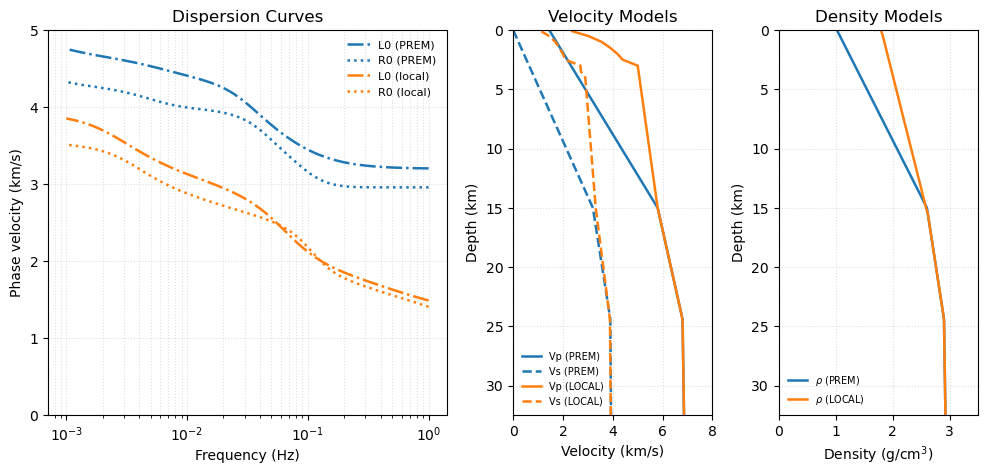

In [ ]:
os.makedirs(path_to_figs, exist_ok=True)
# Nice, simple 3-panel layout:
# - Left: dispersion curves
# - Right-top: Vp and Vs vs depth
# - Right-bottom: density vs depth

# import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# --- adapt these model arrays to your variables ---
# Example expected arrays (1D, same length per model):
# depth_global, vp_global, vs_global, rho_global
# depth_local,  vp_local,  vs_local,  rho_local

fig = plt.figure(figsize=(12, 5))
gs = GridSpec(2, 3, width_ratios=[2.4, 1.2, 1.2], hspace=0.2, wspace=0.25)

ax_disp = fig.add_subplot(gs[:, 0])   # left, spans both rows
ax_vel  = fig.add_subplot(gs[:, 1])   # right top
ax_rho  = fig.add_subplot(gs[:, 2])   # right bottom

# ---------------------------
# Left panel: dispersion
# ---------------------------
ax_disp.plot(1 / L0[0], L0[1], color="tab:blue",   ls="-.", lw=1.8, label="L0 (PREM)")
ax_disp.plot(1 / R0[0], R0[1], color="tab:blue",   ls=":", lw=1.8, label="R0 (PREM)")
ax_disp.plot(1 / L0_local[0], L0_local[1], color="tab:orange", ls="-.", lw=1.8, label="L0 (local)")
ax_disp.plot(1 / R0_local[0], R0_local[1], color="tab:orange", ls=":", lw=1.8, label="R0 (local)")

ax_disp.set_xscale("log")
ax_disp.set_ylim(0, 5)
ax_disp.set_xlabel("Frequency (Hz)")
ax_disp.set_ylabel("Phase velocity (km/s)")
ax_disp.set_title("Dispersion Curves")
ax_disp.grid(True, which="both", ls=":", alpha=0.4)
ax_disp.legend(fontsize=8, frameon=False)

# ---------------------------
# Right-top: Vp & Vs vs depth
# ---------------------------
ax_vel.plot(model_prem["vp"], model_prem["depth"], color="tab:blue",   lw=1.8, label="Vp (PREM)")
ax_vel.plot(model_prem["vs"], model_prem["depth"], color="tab:blue",   lw=1.8, ls="--", label="Vs (PREM)")
ax_vel.plot(model_molasse["vp"],  model_molasse["depth"],  color="tab:orange", lw=1.8, label="Vp (LOCAL)")
ax_vel.plot(model_molasse["vs"],  model_molasse["depth"],  color="tab:orange", lw=1.8, ls="--", label="Vs (LOCAL)")

ax_vel.set_ylabel("Depth (km)")
ax_vel.set_xlabel("Velocity (km/s)")
ax_vel.set_title("Velocity Models")
ax_vel.grid(True, ls=":", alpha=0.4)
ax_vel.legend(fontsize=7, frameon=False, ncol=1)

ax_vel.set_ylim(model_molasse["depth"].max(), 0)
ax_vel.set_xlim(0, 8)

# ---------------------------
# Right-bottom: density vs depth
# ---------------------------
ax_rho.plot(model_prem["rho"], model_prem["depth"], color="tab:blue",   lw=1.8, label=r"$\rho$ (PREM)")
ax_rho.plot(model_molasse["rho"],  model_molasse["depth"],  color="tab:orange", lw=1.8, label=r"$\rho$ (LOCAL)")

ax_rho.set_ylim(model_molasse["depth"].max(), 0)
ax_rho.set_xlim(0, 3.5)

ax_rho.set_ylabel("Depth (km)")
ax_rho.set_xlabel("Density (g/cm$^3$)")  # or kg/m³ depending on your units
ax_rho.set_title("Density Models")
ax_rho.grid(True, ls=":", alpha=0.4)
ax_rho.legend(fontsize=7, frameon=False)

plt.tight_layout()
plt.show()

fig.savefig(path_to_figs + "dispersion_models.png", dpi=300, bbox_inches="tight")